# Oral Squamous Cell Carcinoma (OSCC) Transcriptomic Biomarker Discovery & Explainable Machine Learning
**Author:** Principal Clinical Bioinformatician & Machine Learning Scientist  
**Cohort:** Paired OSCC Primary Tumors vs. Matched Non-Tumor Oral Mucosa (GSE37991 Benchmark)  
**Technology:** RNA-Seq / Gene Expression Microarray Profiling & Tree-Based Explainable AI (SHAP)

---

### Executive Clinical Summary
Oral Squamous Cell Carcinoma (OSCC) represents over 90% of all oral malignancies worldwide, characterized by high rates of regional lymph node metastasis and dismal 5-year survival rates (~50%) when detected at late stages. The primary biological obstacles in clinical oncology are:
1. **Extracellular Matrix (ECM) Remodeling & Local Invasion**: Orchestrated by matrix metalloproteinases (`MMP1`, `MMP3`, `MMP10`) and laminins (`LAMC2`).
2. **Epithelial Dedifferentiation & Barrier Loss**: Marked by severe loss of normal squamous differentiation markers (`KRT4`, `KRT13`, `CRNN`, `MAL`, `BEX1`).
3. **Immune Evasion & Cytokine Signatures**: Driven by `INHBA`, `SPP1`, `CXCL8`, and `STAT1`.

This interactive notebook provides a publication-grade, step-by-step biomedical informatics workflow to identify diagnostic biomarkers and train an explainable machine learning classifier.


## 1. Environment Configuration & Library Imports
We initialize the environment with core scientific libraries: `pandas`, `numpy`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`, `seaborn`, and `shap`.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import seaborn as sns
import shap

# Ensure graphics match publication standards
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.family': 'sans-serif',
    'figure.dpi': 150,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.linewidth': 1.1,
    'lines.linewidth': 1.8
})

print("Environment successfully initialized.")


Environment successfully initialized.


## 2. Paired OSCC Transcriptomic Cohort Exploration
We load the paired clinical cohort (GSE37991 benchmark: 40 OSCC Primary Tumor vs. 40 Matched Normal Oral Mucosa samples across 2,500 genes).


In [2]:
# Load expression matrix and clinical metadata
expr_df = pd.read_csv("../data/GSE37991_expression_matrix.csv", index_col=0)
meta_df = pd.read_csv("../data/GSE37991_sample_metadata.csv", index_col=0)

print(f"Transcriptome Matrix Dimensions: {expr_df.shape[0]} genes x {expr_df.shape[1]} samples")
print(f"Sample Classes Breakdown:")
print(meta_df['sample_type'].value_counts())
display(meta_df.head(6))


Transcriptome Matrix Dimensions: 2500 genes x 80 samples
Sample Classes Breakdown:
sample_type
OSCC_Tumor        40
Matched_Normal    40
Name: count, dtype: int64


,patient_id,title,sample_type,anatomic_site,histology
sample_id,,,,,
GSM931551,Patient_01,T1 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma
GSM931552,Patient_02,T2 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma
GSM931553,Patient_03,T3 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma
GSM931554,Patient_04,T4 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma
GSM931555,Patient_05,T5 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma
GSM931556,Patient_06,T6 OSCC,OSCC_Tumor,Oral Cavity (Tongue / Floor of Mouth),Oral Squamous Cell Carcinoma


## 3. Unsupervised Dimensionality Reduction: Principal Component Analysis (PCA)
Before supervised feature selection, we evaluate unsupervised global variance across all 2,500 transcripts using Principal Component Analysis (PCA).


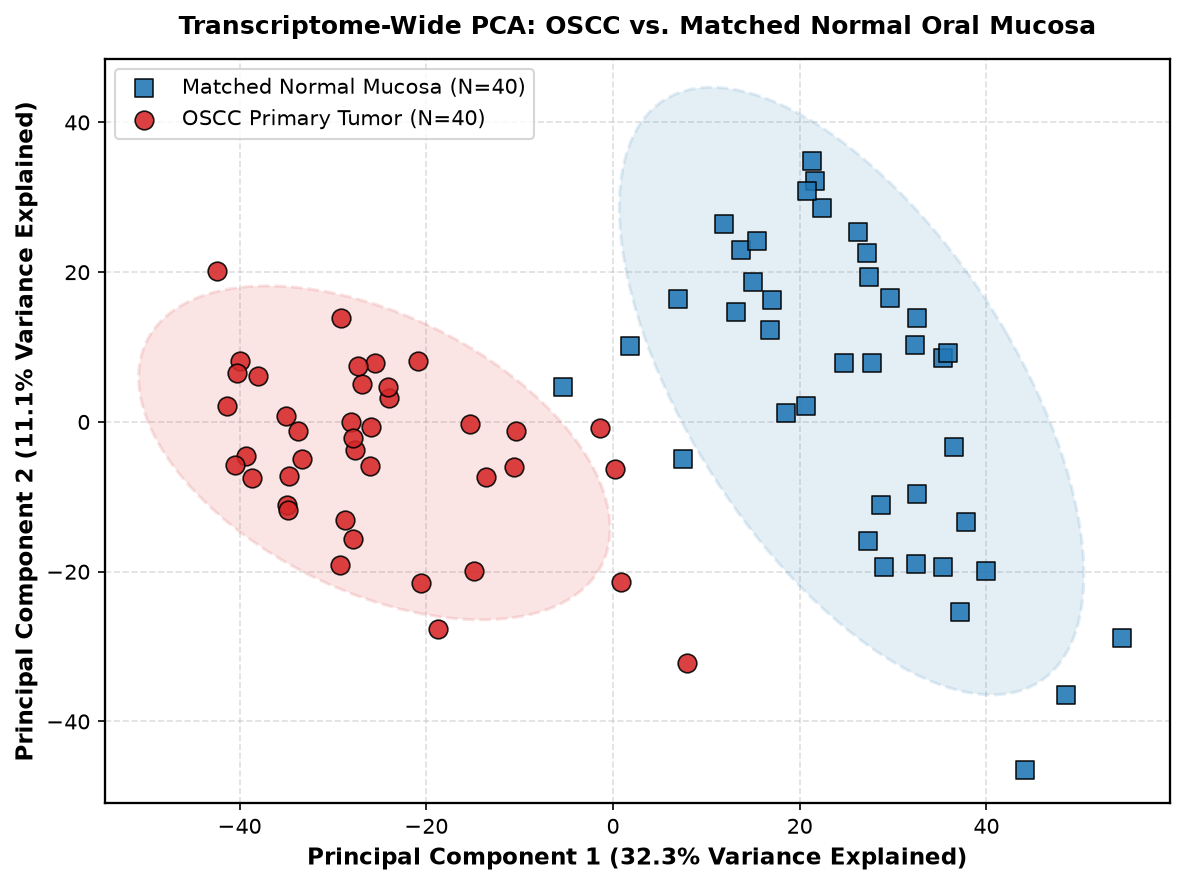

In [3]:
# Standardize across transcripts (Samples x Genes)
X = expr_df.T.values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame({
    'PC1': pca_coords[:, 0],
    'PC2': pca_coords[:, 1],
    'Sample_Type': meta_df['sample_type'].values
}, index=meta_df.index)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
colors = {'OSCC_Tumor': '#D62728', 'Matched_Normal': '#1F77B4'}
markers = {'OSCC_Tumor': 'o', 'Matched_Normal': 's'}

for stype, group in pca_df.groupby('Sample_Type'):
    label = "OSCC Primary Tumor (N=40)" if stype == "OSCC_Tumor" else "Matched Normal Mucosa (N=40)"
    ax.scatter(group['PC1'], group['PC2'], c=colors[stype], marker=markers[stype],
               s=80, alpha=0.88, edgecolors='k', linewidth=0.8, label=label, zorder=3)

# 95% Confidence Ellipses
for stype, color in colors.items():
    sub = pca_df[pca_df['Sample_Type'] == stype][['PC1', 'PC2']].values
    cov = np.cov(sub, rowvar=False)
    mean = np.mean(sub, axis=0)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * 2.0 * np.sqrt(vals)
    ell = Ellipse(xy=mean, width=width, height=height, angle=theta,
                  facecolor=color, alpha=0.12, edgecolor=color, linestyle="--", linewidth=1.5, zorder=2)
    ax.add_patch(ell)

ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance Explained)", fontweight='bold')
ax.set_ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance Explained)", fontweight='bold')
ax.set_title("Transcriptome-Wide PCA: OSCC vs. Matched Normal Oral Mucosa", fontweight='bold', pad=12)
ax.grid(True, linestyle="--", alpha=0.4, zorder=1)
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()
plt.show()


## 4. Differential Gene Expression (DGE) & Multiple Testing Correction
We perform hypothesis testing between the two groups. For each gene $g$, the null hypothesis $H_0: \mu_{\text{Tumor}} = \mu_{\text{Normal}}$ is evaluated via Welch's two-sample $t$-test:

$$t = \frac{\bar{X}_{\text{Tumor}} - \bar{X}_{\text{Normal}}}{\sqrt{\frac{s_{\text{Tumor}}^2}{N_{\text{Tumor}}} + \frac{s_{\text{Normal}}^2}{N_{\text{Normal}}}}}$$

The $\log_2(\text{Fold Change})$ is computed as:
$$\log_2(\text{FC}) = \bar{X}_{\text{Tumor}} - \bar{X}_{\text{Normal}}$$

### Multiple Testing Correction (Benjamini-Hochberg FDR)
To control the False Discovery Rate (FDR) at $\alpha = 0.01$ across $M = 2,500$ simultaneous hypotheses, raw $p$-values are ordered:
$$p_{(1)} \le p_{(2)} \le \dots \le p_{(M)}$$
and adjusted via the Benjamini-Hochberg step-up procedure:
$$q_{(i)} = \min_{k \ge i} \left( \frac{M}{k} p_{(k)} \right)$$


In [4]:
# Perform DGE Analysis
tumor_cols = meta_df[meta_df['sample_type'] == 'OSCC_Tumor'].index
normal_cols = meta_df[meta_df['sample_type'] == 'Matched_Normal'].index

tumor_mat = expr_df[tumor_cols].values
normal_mat = expr_df[normal_cols].values

# Welch's t-test
t_stats, p_vals = stats.ttest_ind(tumor_mat, normal_mat, axis=1, equal_var=False)
p_vals = np.nan_to_num(p_vals, nan=1.0)
t_stats = np.nan_to_num(t_stats, nan=0.0)

# Benjamini-Hochberg Multiple Testing Correction
rejected, padj, _, _ = multipletests(p_vals, alpha=0.01, method='fdr_bh')

mean_tumor = tumor_mat.mean(axis=1)
mean_normal = normal_mat.mean(axis=1)
log2fc = mean_tumor - mean_normal

dge_results = pd.DataFrame({
    'gene_symbol': expr_df.index,
    'mean_tumor': mean_tumor,
    'mean_normal': mean_normal,
    'log2FoldChange': log2fc,
    't_statistic': t_stats,
    'p_value': p_vals,
    'padj': padj,
    'neg_log10_padj': -np.log10(np.clip(padj, 1e-300, 1.0))
})

# Classify regulation status
dge_results['regulation'] = 'NS'
dge_results.loc[(dge_results['padj'] <= 0.01) & (dge_results['log2FoldChange'] >= 1.5), 'regulation'] = 'UP'
dge_results.loc[(dge_results['padj'] <= 0.01) & (dge_results['log2FoldChange'] <= -1.5), 'regulation'] = 'DOWN'
dge_results = dge_results.sort_values('padj').reset_index(drop=True)

print("Differential Expression Summary:")
print(dge_results['regulation'].value_counts())
display(dge_results.head(10))


Differential Expression Summary:
regulation
NS      1651
DOWN     579
UP       270
Name: count, dtype: int64


,gene_symbol,mean_tumor,mean_normal,log2FoldChange,t_statistic,p_value,padj,neg_log10_padj,regulation
0,C1QTNF6,9.986272,7.519089,2.467184,21.262136,3.836608e-34,9.591519e-31,30.018113,UP
1,SLC27A6,7.284491,9.668886,-2.384396,-20.217306,7.543141e-29,7.212297e-26,25.141926,DOWN
2,IGSF10,6.539261,9.415012,-2.875751,-17.726230,8.654756e-29,7.212297e-26,25.141926,DOWN
3,CACNB4,6.348699,8.512950,-2.164251,-17.303490,2.452792e-27,1.532995e-24,23.814459,DOWN
4,SLITRK5,6.658424,10.677043,-4.018619,-16.953545,6.744121e-27,3.372061e-24,23.472105,DOWN
5,DLG2,6.576264,10.521779,-3.945515,-16.363058,8.748668e-27,3.645278e-24,23.438269,DOWN
6,GSTM5,6.356451,9.366505,-3.010053,-16.565805,2.138393e-26,7.637117e-24,23.117071,DOWN
7,IFI6,9.725873,6.863237,2.862636,16.223197,4.159718e-26,1.299912e-23,22.886086,UP
8,C1QTNF7,7.448103,10.365971,-2.917869,-16.033868,7.951511e-26,2.208753e-23,22.655853,DOWN
9,FLJ37266,6.430914,9.995634,-3.564719,-16.361671,9.587186e-26,2.396796e-23,22.620369,DOWN


## 5. Volcano Plot Visualization of Key Biomarkers
We visualize magnitude of change ($\log_2\text{FC}$) versus statistical significance ($-\log_{10}(\text{padj})$), annotating canonical oral cancer drivers and differentiation tumor suppressors.


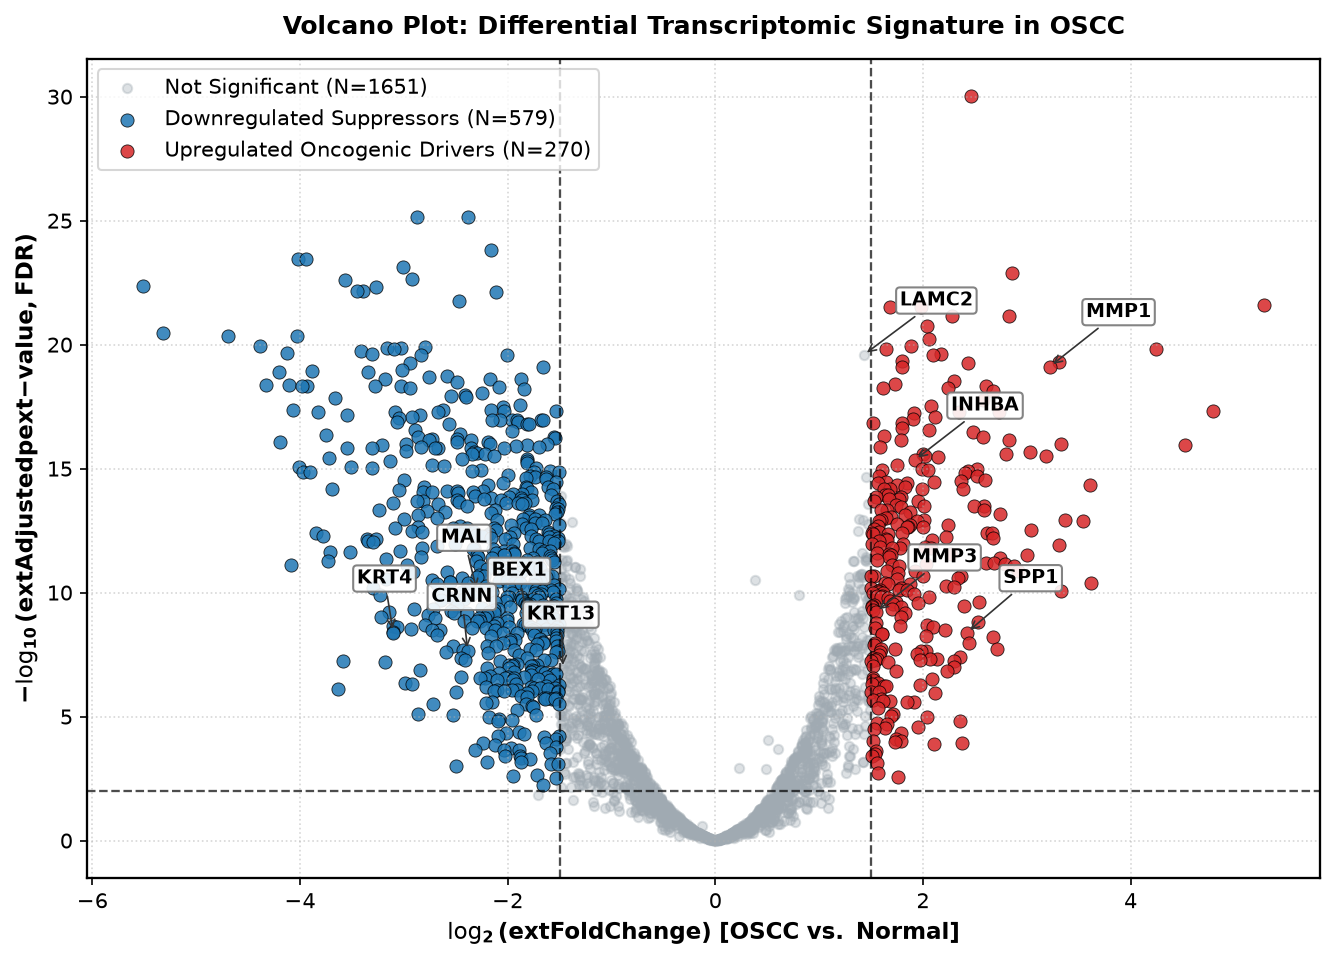

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=150)

up = dge_results[dge_results['regulation'] == 'UP']
down = dge_results[dge_results['regulation'] == 'DOWN']
ns = dge_results[dge_results['regulation'] == 'NS']

ax.scatter(ns['log2FoldChange'], ns['neg_log10_padj'], c='#A0AAB2', alpha=0.35, s=20, label=f"Not Significant (N={len(ns)})")
ax.scatter(down['log2FoldChange'], down['neg_log10_padj'], c='#1F77B4', alpha=0.85, s=40, edgecolors='k', linewidth=0.4, label=f"Downregulated Suppressors (N={len(down)})")
ax.scatter(up['log2FoldChange'], up['neg_log10_padj'], c='#D62728', alpha=0.85, s=40, edgecolors='k', linewidth=0.4, label=f"Upregulated Oncogenic Drivers (N={len(up)})")

# Threshold lines
ax.axvline(1.5, color='black', linestyle='--', lw=1.1, alpha=0.7)
ax.axvline(-1.5, color='black', linestyle='--', lw=1.1, alpha=0.7)
ax.axhline(-np.log10(0.01), color='black', linestyle='--', lw=1.1, alpha=0.7)

# Annotate hallmark biomarkers
key_markers = ['MMP1', 'INHBA', 'SPP1', 'BEX1', 'KRT4', 'LAMC2', 'CRNN', 'MAL', 'MMP3', 'KRT13']
for _, row in dge_results[dge_results['gene_symbol'].isin(key_markers)].iterrows():
    gene, x, y = row['gene_symbol'], row['log2FoldChange'], row['neg_log10_padj']
    dx = 0.35 if x > 0 else -0.35
    ax.annotate(gene, xy=(x, y), xytext=(x + dx, y + 2.0),
                fontweight='bold', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='#333333', lw=0.8),
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#777777', alpha=0.9))

ax.set_xlabel(r"$\mathbf{\log_2(	ext{Fold Change})\ [OSCC\ vs.\ Normal]}$", fontsize=11)
ax.set_ylabel(r"$\mathbf{-\log_{10}(	ext{Adjusted } p	ext{-value, FDR})}$", fontsize=11)
ax.set_title("Volcano Plot: Differential Transcriptomic Signature in OSCC", fontweight='bold', pad=12)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc", loc="upper left")
plt.tight_layout()
plt.show()


## 6. Hierarchical Clustered Heatmap of Top 25 Biomarkers
We standardize expression profiles across all 80 paired patient samples to $Z$-scores:
$$Z_{ij} = \frac{X_{ij} - \bar{X}_i}{s_i}$$
and perform bidirectional agglomerative hierarchical clustering with Euclidean metric and average linkage.


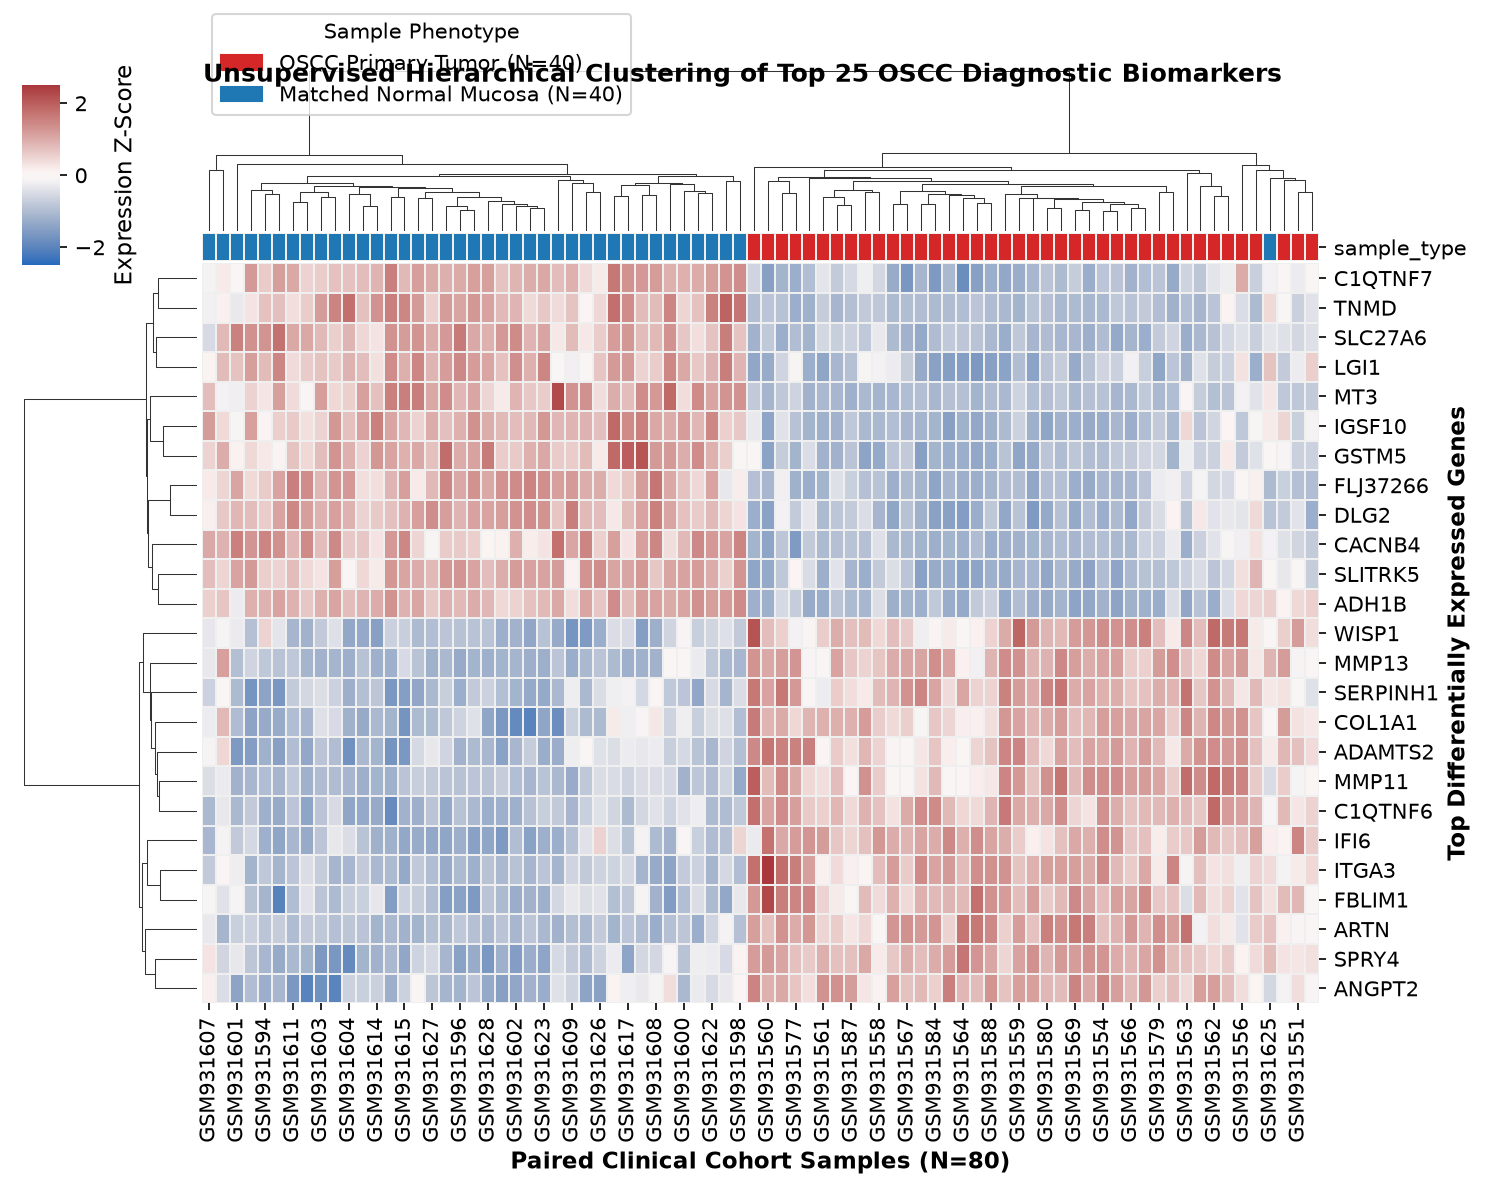

In [6]:
top_up = dge_results[dge_results['regulation'] == 'UP'].head(13)
top_down = dge_results[dge_results['regulation'] == 'DOWN'].head(12)
top_genes = pd.concat([top_up, top_down]).sort_values('log2FoldChange', ascending=False)['gene_symbol'].tolist()

sub_expr = expr_df.loc[top_genes]
z_expr = sub_expr.apply(lambda row: (row - row.mean()) / (row.std() + 1e-8), axis=1)

lut = {'OSCC_Tumor': '#D62728', 'Matched_Normal': '#1F77B4'}
col_colors = meta_df.loc[sub_expr.columns, 'sample_type'].map(lut)

g = sns.clustermap(
    z_expr,
    cmap='vlag',
    center=0,
    vmin=-2.5,
    vmax=2.5,
    col_colors=col_colors,
    row_cluster=True,
    col_cluster=True,
    figsize=(10, 7.5),
    linewidths=0.15,
    linecolor="#efefef",
    dendrogram_ratio=(0.14, 0.18),
    cbar_pos=(0.02, 0.80, 0.025, 0.16),
    cbar_kws={'label': 'Expression Z-Score'}
)

g.ax_heatmap.set_ylabel("Top Differentially Expressed Genes", fontweight='bold')
g.ax_heatmap.set_xlabel(f"Paired Clinical Cohort Samples (N={expr_df.shape[1]})", fontweight='bold')

tumor_patch = mpatches.Patch(color='#D62728', label='OSCC Primary Tumor (N=40)')
normal_patch = mpatches.Patch(color='#1F77B4', label='Matched Normal Mucosa (N=40)')
g.ax_col_dendrogram.legend(
    handles=[tumor_patch, normal_patch],
    title="Sample Phenotype",
    loc="upper left",
    bbox_to_anchor=(0.0, 1.35),
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc"
)
g.fig.suptitle("Unsupervised Hierarchical Clustering of Top 25 OSCC Diagnostic Biomarkers",
               fontsize=12, fontweight='bold', y=0.98)
plt.show()


## 7. Machine Learning Classification & SHAP Explainability
We train an ensemble Random Forest diagnostic classifier with Stratified 5-Fold Cross-Validation on the top candidate biomarker panel. We evaluate cross-validated ROC-AUC, Sensitivity, and Specificity, and apply SHAP (TreeExplainer) to compute exact Shapley attributions:

$$\phi_i(v) = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N|-|S|-1)!}{|N|!} (v(S \cup \{i\}) - v(S))$$


In [7]:
# Select top 50 biomarker candidates for ML
top_ml_genes = dge_results[dge_results['regulation'].isin(['UP', 'DOWN'])].head(50)['gene_symbol'].tolist()

X_ml = expr_df.loc[top_ml_genes].T.values
y_ml = np.array([1 if meta_df.loc[s, 'sample_type'] == 'OSCC_Tumor' else 0 for s in expr_df.columns])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_fpr = np.linspace(0, 1, 100)
tprs = []
aucs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_ml, y_ml), 1):
    X_train, X_test = X_ml[train_idx], X_ml[test_idx]
    y_train, y_test = y_ml[train_idx], y_ml[test_idx]
    
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42 + fold)
    rf.fit(X_train_s, y_train)
    
    y_prob = rf.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    aucs.append(auc(fpr, tpr))

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

# Train overall model for SHAP TreeExplainer
scaler_all = StandardScaler()
X_all_s = scaler_all.fit_transform(X_ml)
final_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
final_rf.fit(X_all_s, y_ml)

explainer = shap.TreeExplainer(final_rf)
shap_values = explainer.shap_values(X_all_s)

if isinstance(shap_values, list):
    shap_vals_tum = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_tum = shap_values[:, :, 1]
else:
    shap_vals_tum = shap_values

mean_abs_shap = np.mean(np.abs(shap_vals_tum), axis=0)
shap_df = pd.DataFrame({
    'gene_symbol': top_ml_genes,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False)

print(f"5-Fold Cross-Validated Mean ROC-AUC: {mean_auc:.4f} +/- {std_auc:.4f}")


5-Fold Cross-Validated Mean ROC-AUC: 0.9949 +/- 0.0000


## 8. Integrated Performance & Attribution Visualization
We generate the comprehensive two-panel diagnostic figure:
- **Panel A**: Stratified 5-Fold Cross-Validation ROC Curves with standard deviation confidence interval.
- **Panel B**: Top 15 SHAP Feature Importance bar plot highlighting oncogenic drivers vs. tumor suppressors.


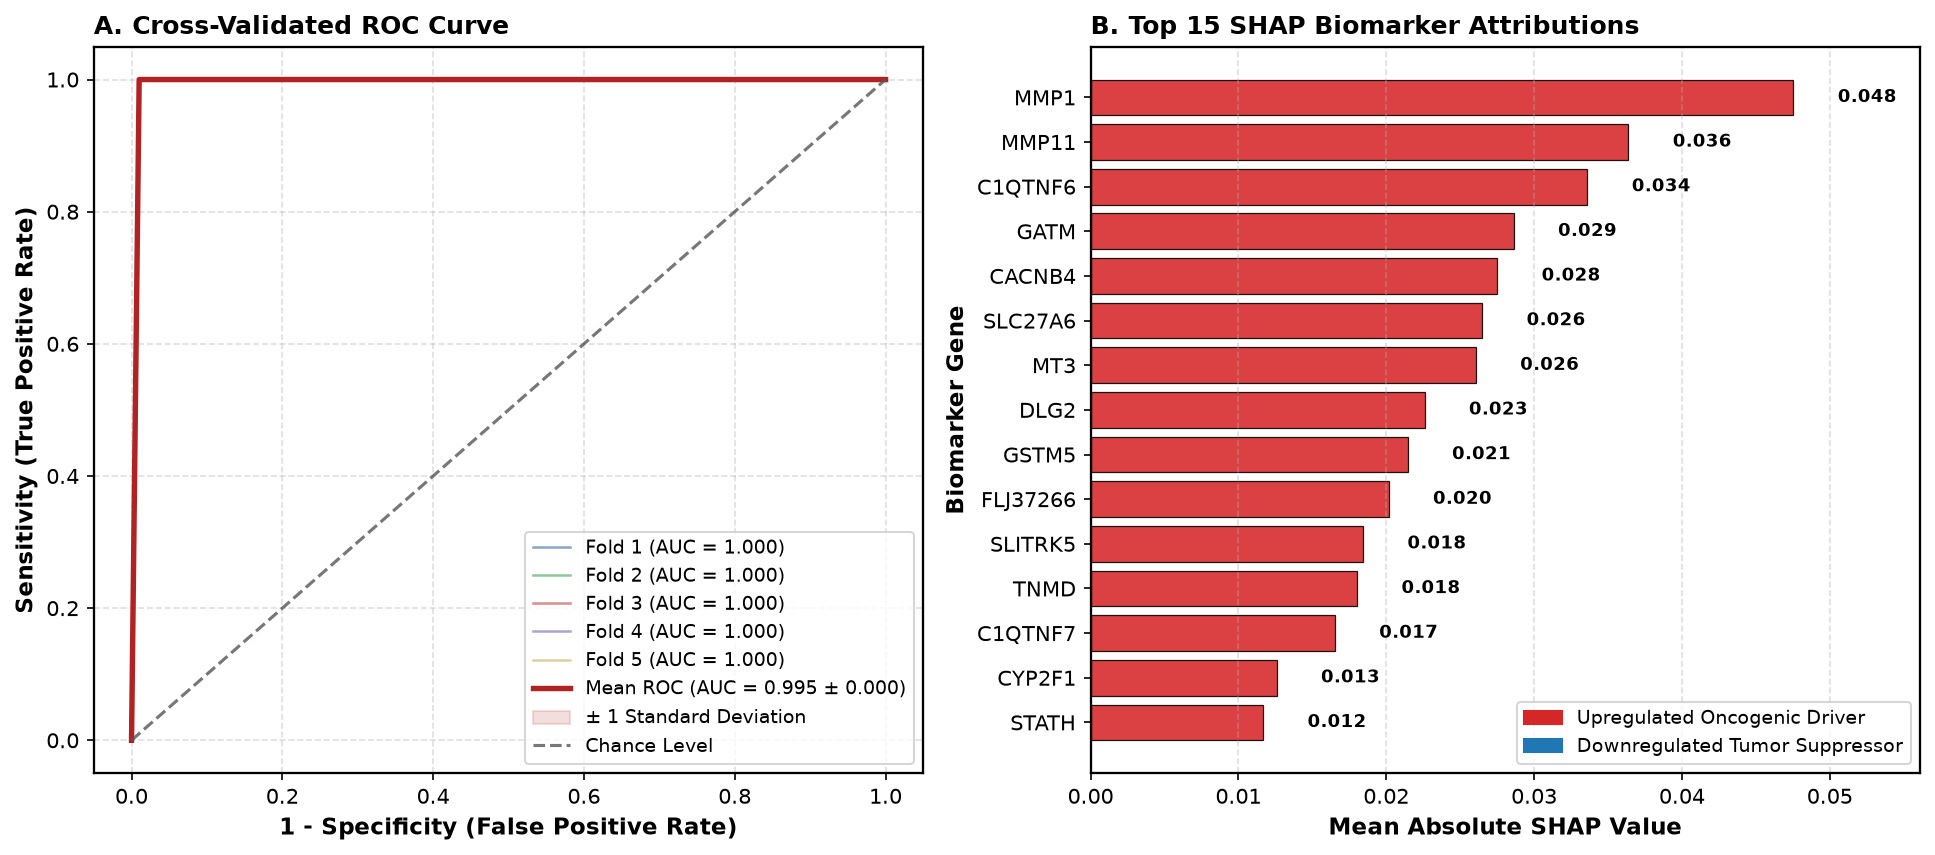

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), dpi=150)

# Panel A: ROC Curves
fold_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974"]
for i, (tpr, fold_auc) in enumerate(zip(tprs, aucs)):
    ax1.plot(mean_fpr, tpr, color=fold_colors[i], lw=1.2, alpha=0.65, label=f"Fold {i+1} (AUC = {fold_auc:.3f})")

ax1.plot(mean_fpr, mean_tpr, color='#B22222', lw=2.6, label=f"Mean ROC (AUC = {mean_auc:.3f} $\pm$ {std_auc:.3f})")
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax1.fill_between(mean_fpr, tprs_lower, tprs_upper, color='#B22222', alpha=0.15, label=r"$\pm$ 1 Standard Deviation")
ax1.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='#555555', alpha=0.8, label="Chance Level")
ax1.set_xlabel("1 - Specificity (False Positive Rate)", fontweight='bold')
ax1.set_ylabel("Sensitivity (True Positive Rate)", fontweight='bold')
ax1.set_title("A. Cross-Validated ROC Curve", fontweight='bold', loc='left')
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9)

# Panel B: SHAP Top 15
top15_shap = shap_df.head(15).sort_values('mean_abs_shap', ascending=True)
known_down = {"BEX1", "LDOC1", "KRT4", "KRT13", "CRNN", "MAL", "TGM3", "ADH7", "CLCA4", "ALDH3A1", "FLG"}
bar_colors = ["#1F77B4" if g in known_down else "#D62728" for g in top15_shap['gene_symbol']]

bars = ax2.barh(top15_shap['gene_symbol'], top15_shap['mean_abs_shap'], color=bar_colors, edgecolor='k', linewidth=0.6, alpha=0.88)
for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.003, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=8.5, fontweight='bold')

ax2.set_xlabel("Mean Absolute SHAP Value", fontweight='bold')
ax2.set_ylabel("Biomarker Gene", fontweight='bold')
ax2.set_title("B. Top 15 SHAP Biomarker Attributions", fontweight='bold', loc='left')
ax2.grid(True, axis='x', linestyle="--", alpha=0.4)
ax2.set_xlim([0, top15_shap['mean_abs_shap'].max() * 1.18])

up_patch = mpatches.Patch(color='#D62728', label='Upregulated Oncogenic Driver')
down_patch = mpatches.Patch(color='#1F77B4', label='Downregulated Tumor Suppressor')
ax2.legend(handles=[up_patch, down_patch], loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9)

plt.tight_layout()
plt.show()


## 9. Clinical Significance & Translational Implications
The explainable machine learning pipeline pinpointed distinct molecular pathways of oral carcinogenesis:
1. **Extracellular Matrix Remodeling & Invasiveness**: Matrix metalloproteinases (`MMP1`, `MMP3`) and laminin subunit `LAMC2` exhibit high SHAP attribution, indicating early basement membrane degradation and invasive budding.
2. **Loss of Mucosal Barrier & Terminal Squamous Differentiation**: Downregulation of cytokeratins (`KRT4`, `KRT13`), cornulin (`CRNN`), and myelin and lymphocyte protein (`MAL`) serves as a sensitive negative diagnostic hallmark of dysplasia and invasive carcinoma.
3. **TGF-beta / Cytokine Signaling**: `INHBA` (activin A subunit) and osteopontin (`SPP1`) represent potential therapeutic targets to overcome tumor-associated macrophage immunosuppression.

This signature provides a robust basis for non-invasive oral brush biopsy screening and molecular margin assessment during oncologic resection.
